# The Day After: results notebook

**Which farmland in Khan Younis (Gaza) could feed people first after a ceasefire?** Satellite AI, checked against UN expert damage maps.

*This project is a prototype, not agricultural or humanitarian advice.*

This notebook shows every result of the project with its output visible. It reads only small files stored in the repository
(`results/`). The scores are **recomputed here** from the per-pixel answers that were saved when each test was run, so you can check them
without trusting my tables. The full pipeline (satellite download, features, training) is in `src/`, and the plain-words explanation of
every step is in `docs/explainers.md`.

In [1]:
import json, gzip, io
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
R = ROOT / "results"
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 200)
load = lambda p: json.loads((R / p).read_text())

def counts(y, p):
    """tn, fp, fn, tp: y is the UN label (1 = damaged), p the method's answer."""
    y, p = np.asarray(y), np.asarray(p)
    return int(((y == 0) & (p == 0)).sum()), int(((y == 0) & (p == 1)).sum()), int(((y == 1) & (p == 0)).sum()), int(((y == 1) & (p == 1)).sum())

def macro_f1(tn, fp, fn, tp):
    """F1 for 'damaged' and for 'intact', averaged. 1 = perfect; always answering 'damaged' gives under 0.5."""
    f = lambda a, b, c: 2 * a / (2 * a + b + c) if 2 * a + b + c else 0.0
    return (f(tp, fp, fn) + f(tn, fn, fp)) / 2

def rescore(file, methods):
    """Recompute every score from a file of saved per-pixel answers."""
    A = pd.read_csv(io.BytesIO(gzip.decompress((R / file).read_bytes())))
    rows = []
    for exam, prefix, sel in (("Dec 2024", "pred__", A.date == "2024-12"), ("Jul 2025", "pred__", A.date == "2025-07"), ("Forward in time", "time__", A.date == "2025-07")):
        for m in methods:
            tn, fp, fn, tp = counts(A.label[sel], A[prefix + m][sel])
            rows.append({"exam": exam, "method": m, "pixels": int(sel.sum()), "UN intact, says intact": tn, "UN intact, says damaged": fp,
                         "UN damaged, says intact": fn, "UN damaged, says damaged": tp, "accuracy": round((tn + tp) / sel.sum(), 3), "macro F1": round(macro_f1(tn, fp, fn, tp), 3)})
    return pd.DataFrame(rows)
print("results folder:", R.resolve().name, "| files:", len(list(R.rglob("*.*"))))

results folder: results | files: 129


## 1. The answer key: UN damage maps
UNOSAT and FAO mapped Gaza's cropland as *damaged* or *non-affected* 18 times (Oct 2023 to Jul 2025). I put each map on my 10 m grid.
The table shows the damaged area in Khan Younis governorate for each map. The last cell compares these hectares with the figure FAO published.

In [2]:
h = load("label_history.json")
t = pd.DataFrame(h["snapshots"])[["snapshot", "cropland_ha", "damaged_ha", "damaged_pct"]]
display(t)
x = h["fao_cross_check_march_2025"]
print("March 2025, Khan Younis damaged share. FAO published:", x["fao_khan_younis"]["damaged_pct"], "%   this project:", x["ours_khan_younis"]["damaged_pct"], "%")

,snapshot,cropland_ha,damaged_ha,damaged_pct
0,20231027,4206.6,242.0,5.8
1,20231126,4206.6,468.9,11.1
2,20231226,4206.6,882.8,21.0
3,20240130,4206.6,1292.0,30.7
4,20240224,4206.6,1425.5,33.9
5,20240330,4206.6,1760.3,41.8
6,20240429,4206.6,1937.9,46.1
7,20240529,4206.6,2345.1,55.7
8,20240628,4222.7,2454.0,58.1
9,20240728,4222.7,2502.2,59.3


March 2025, Khan Younis damaged share. FAO published: 75.5 %   this project: 75.9 %


## 2. The split: land the model never sees
Neighbouring pixels look alike, so a random split would let a model copy its neighbours. I cut the governorate into 1 km blocks and locked
whole blocks away for testing. Training pixels within 100 m of a test block were dropped.

,blocks,pixels,hectares,share of cropland,damaged share Dec 2024,damaged share Jul 2025
train,93.0,258219.0,2582.2,0.6115,0.6614,0.8015
test,40.0,125282.0,1252.8,0.2967,0.7191,0.8389
buffer_dropped,,38772,387.7,0.0918,0.7213,0.8388


closest training pixel to test land: 110.0 m


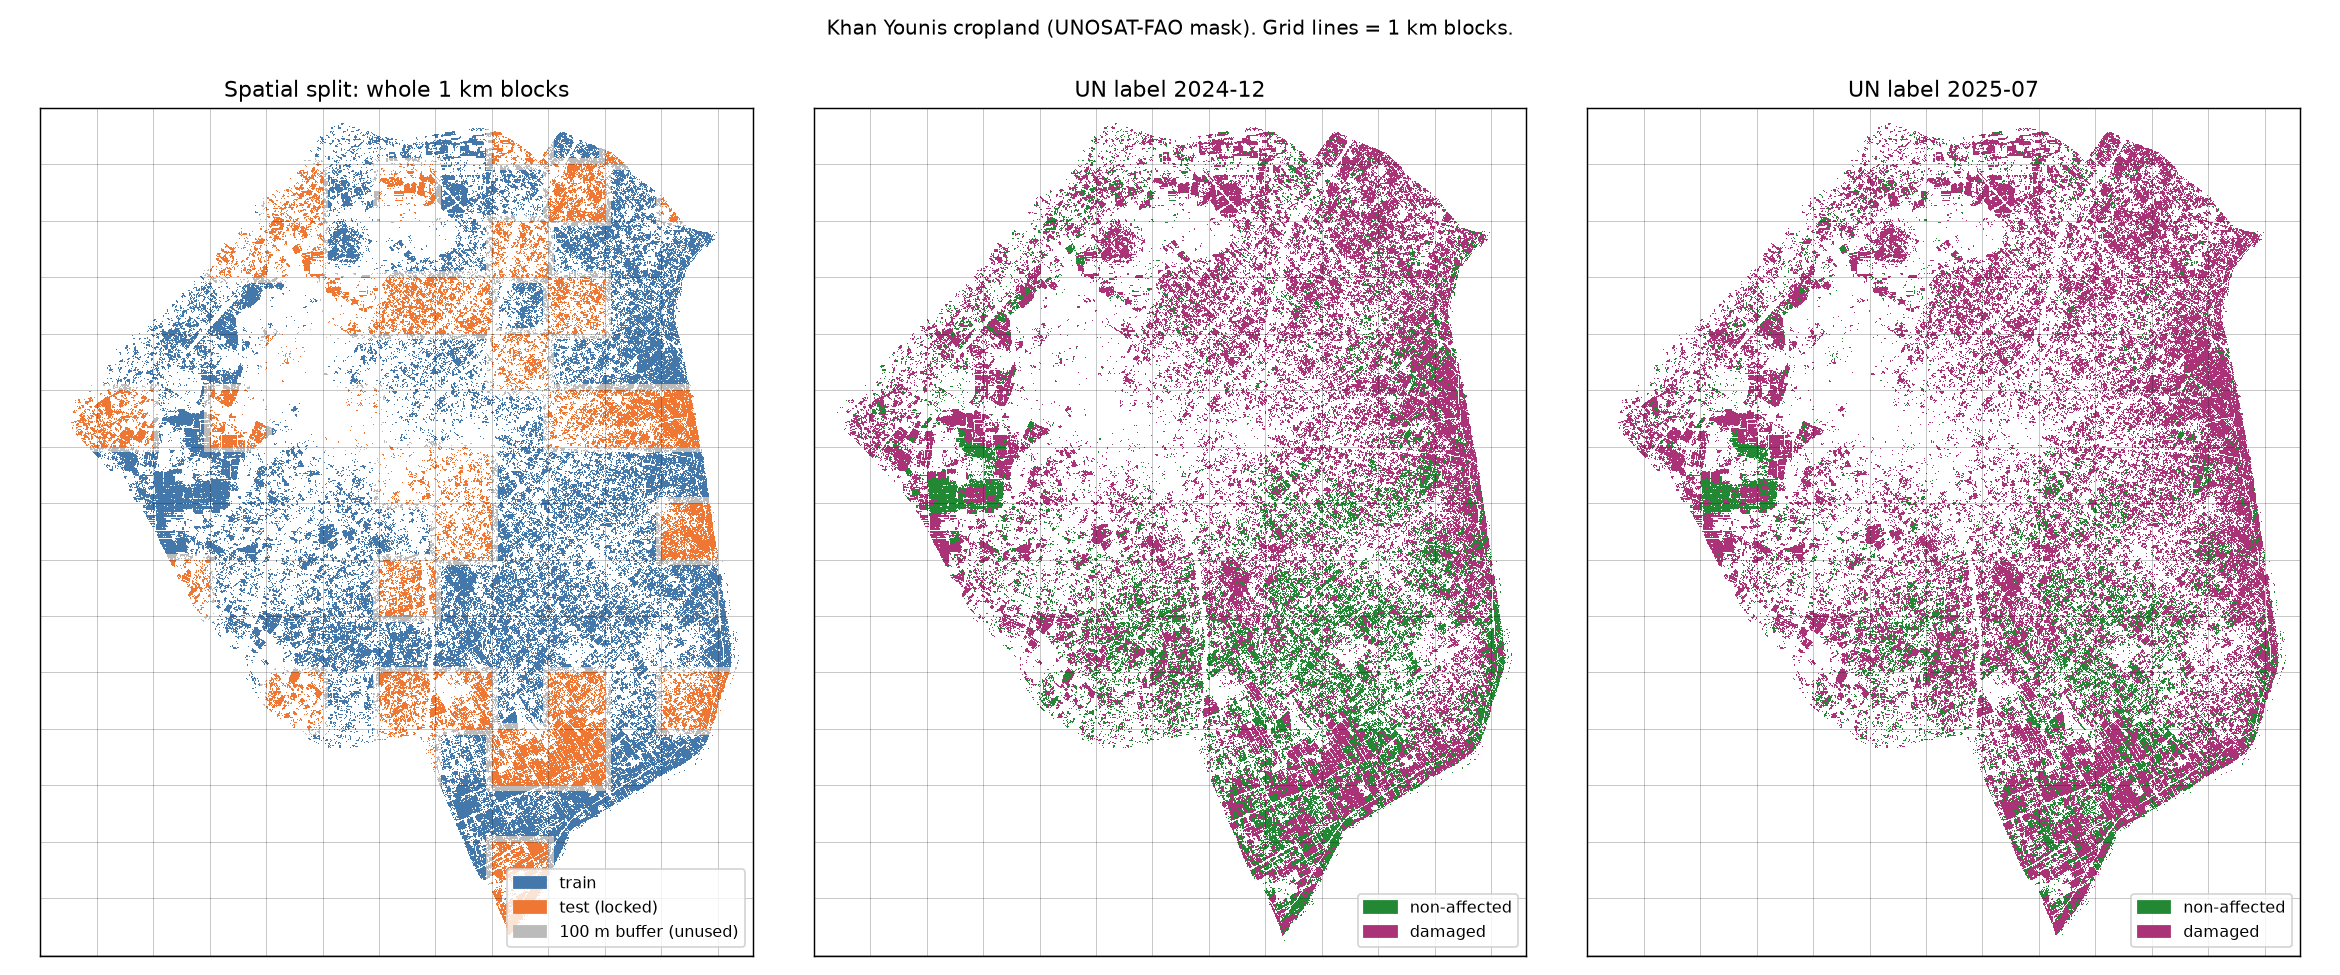

In [3]:
s = load("split_summary.json")
display(pd.DataFrame({k: {"blocks": s["n_blocks"].get(k, ""), "pixels": v["n_px"], "hectares": v["hectares"], "share of cropland": v["share_of_cropland"],
                          "damaged share Dec 2024": v["2024-12"]["damaged_share"], "damaged share Jul 2025": v["2025-07"]["damaged_share"]} for k, v in s["pixels"].items()}).T)
print("closest training pixel to test land:", s["min_train_to_test_distance_m"], "m")
display(Image(str(R / "figures" / "split_map.png"), width=950))

## 3. First model (v1): one month of images
v1 compared one month with the same month of 2022. Before the test land was opened, I wrote the rules in `docs/test_plan.md`.
The next cell **recomputes** the v1 test scores from the saved answers (`results/test/predictions_main.csv.gz`).

In [4]:
u = load("test/unlock.json"); print("test land opened once at", u["opened_at"], "| code version", u["code_version_git_commit"][:7], "|", u["n_rows"], "pixel-dates in", u["n_blocks"], "blocks")
v1 = rescore("test/predictions_main.csv.gz", ["ndvi_drop", "rf_all"])
display(v1)
saved = pd.read_csv(R / "test" / "scores.csv").set_index(["exam", "method"])
print("largest difference from the scores I reported:", max(abs(r["macro F1"] - saved.loc[({"Dec 2024": "same-date 2024-12", "Jul 2025": "same-date 2025-07", "Forward in time": "time 2024-12->2025-07"}[r["exam"]], r["method"]), "macro_f1"]) for _, r in v1.iterrows()).round(4))

test land opened once at 2026-11-14T21:39:39+02:00 | code version 2253c93 | 250536 pixel-dates in 40 blocks


,exam,method,pixels,"UN intact, says intact","UN intact, says damaged","UN damaged, says intact","UN damaged, says damaged",accuracy,macro F1
0,Dec 2024,ndvi_drop,125282,23717,11469,30529,59567,0.665,0.635
1,Dec 2024,rf_all,125282,28902,6284,23633,66463,0.761,0.738
2,Jul 2025,ndvi_drop,125254,13701,6464,39360,65729,0.634,0.558
3,Jul 2025,rf_all,125254,14245,5920,16024,89065,0.825,0.728
4,Forward in time,ndvi_drop,125254,18090,2075,54781,50308,0.546,0.514
5,Forward in time,rf_all,125254,11011,9154,14111,90978,0.814,0.686


largest difference from the scores I reported: 0.0005


## 4. Improved model (v2): each field against its own normal, month after month
v1 failed on fields that are bare every December or July. v2 gives the model each pixel's monthly history against its own 2017-2022 normal,
and it learns from all 18 UN maps. It was compared with other candidates **on training land only** (cross-validation):

In [5]:
c = pd.read_csv(R / "v2" / "cv_candidates.csv").rename(columns={"f1_2024-12": "Dec 2024", "f1_2025-07": "Jul 2025", "headline_mean": "mean of the two",
        "clean_pixels_mean": "on clean pixels", "all_18_months_mean": "mean of all 18 months"})
display(c)
ch = load("v2/chosen.json")
print("my pre-set rule picked:", ch["rule_pick"], "| I chose:", ch["chosen"], "| departed from the rule:", ch["departed_from_rule"])
print("why: the rule's pick learned from two months only. Mean score over all 18 months:", {k: round(v, 3) for k, v in ch["all_18_months_mean"].items() if k in ("hist_2m", "hist_18m")})

,candidate,Dec 2024,Jul 2025,mean of the two,on clean pixels,mean of all 18 months
0,majority,0.3981,0.4449,0.4215,0.4424,0.4039
1,v1_rule_ndvi_drop,0.6371,0.5910,0.6140,0.5798,NaN
2,rule_now,0.7258,0.6616,0.6937,0.6828,0.7683
3,rule_war,0.7719,0.7749,0.7734,0.8052,0.7993
4,v1_rf_all,0.7495,0.7455,0.7475,0.7726,NaN
5,hist_2m,0.8604,0.8701,0.8652,0.9040,0.8031
6,hist_18m,0.8529,0.8476,0.8502,0.8924,0.8492
7,hist_18m_w,0.8516,0.8445,0.8480,0.8932,0.8474
8,hist_18m_w_nb,0.8529,0.8465,0.8497,0.8973,0.8480
9,rf_18m_w,0.8292,0.8441,0.8366,0.8805,0.8420


my pre-set rule picked: hist_2m | I chose: hist_18m | departed from the rule: True
why: the rule's pick learned from two months only. Mean score over all 18 months: {'hist_2m': 0.803, 'hist_18m': 0.849}


The rules for the second look at the test land were written in `docs/test_plan_v2.md` and pushed first. The next cell **recomputes**
the scores from the saved answers. `rule_war` is the simple rival: "damaged if the worst monthly greenness drop since Oct 2023 is below a threshold".

In [6]:
u = load("test_v2/unlock.json"); print("second and last look at", u["opened_at"], "| code version", u["code_version_git_commit"][:7])
v2 = rescore("test_v2/predictions_main.csv.gz", ["rule_war", "rf_all", "v2_2m", "v2"])
display(v2)
g = load("test_v2/gap.json")
display(pd.DataFrame([{"comparison": v["model"] + " minus " + v["baseline"], "exam": k.split(" | ")[0], "gap in macro F1": v["macro_f1_gap"], "95% range, low": v["ci_low"], "95% range, high": v["ci_high"],
                       "whole range above zero": v["ci_low"] > 0} for k, v in g.items()]))

second and last look at 2026-11-15T00:05:04+02:00 | code version f611891


,exam,method,pixels,"UN intact, says intact","UN intact, says damaged","UN damaged, says intact","UN damaged, says damaged",accuracy,macro F1
0,Dec 2024,rule_war,125282,25282,9904,12460,77636,0.821,0.784
1,Dec 2024,rf_all,125282,28902,6284,23633,66463,0.761,0.738
2,Dec 2024,v2_2m,125282,29773,5413,7808,82288,0.894,0.872
3,Dec 2024,v2,125282,27731,7455,7097,82999,0.884,0.856
4,Jul 2025,rule_war,125254,13245,6920,8145,96944,0.880,0.783
5,Jul 2025,rf_all,125254,14245,5920,16024,89065,0.825,0.728
6,Jul 2025,v2_2m,125254,15921,4244,4532,100557,0.930,0.871
7,Jul 2025,v2,125254,15283,4882,6310,98779,0.911,0.839
8,Forward in time,rule_war,125254,14983,5182,12467,92622,0.859,0.771
9,Forward in time,rf_all,125254,11011,9154,14111,90978,0.814,0.686


,comparison,exam,gap in macro F1,"95% range, low","95% range, high",whole range above zero
0,v2 minus rule_war,same-date 2024-12,0.0721,0.0599,0.0874,True
1,v2 minus rule_war,same-date 2025-07,0.0565,0.0404,0.0755,True
2,v2 minus rule_war,time 2024-12->2025-07,0.0182,-0.0023,0.0411,False
3,v2 minus rf_all,same-date 2024-12,0.1182,0.0981,0.1390,True
4,v2 minus rf_all,same-date 2025-07,0.1116,0.0906,0.1364,True
5,v2 minus rf_all,time 2024-12->2025-07,0.1029,0.0811,0.1300,True
6,v2 minus ndvi_drop,same-date 2024-12,0.2209,0.1891,0.2575,True
7,v2 minus ndvi_drop,same-date 2025-07,0.2813,0.2395,0.3242,True
8,v2 minus ndvi_drop,time 2024-12->2025-07,0.2754,0.2345,0.3181,True


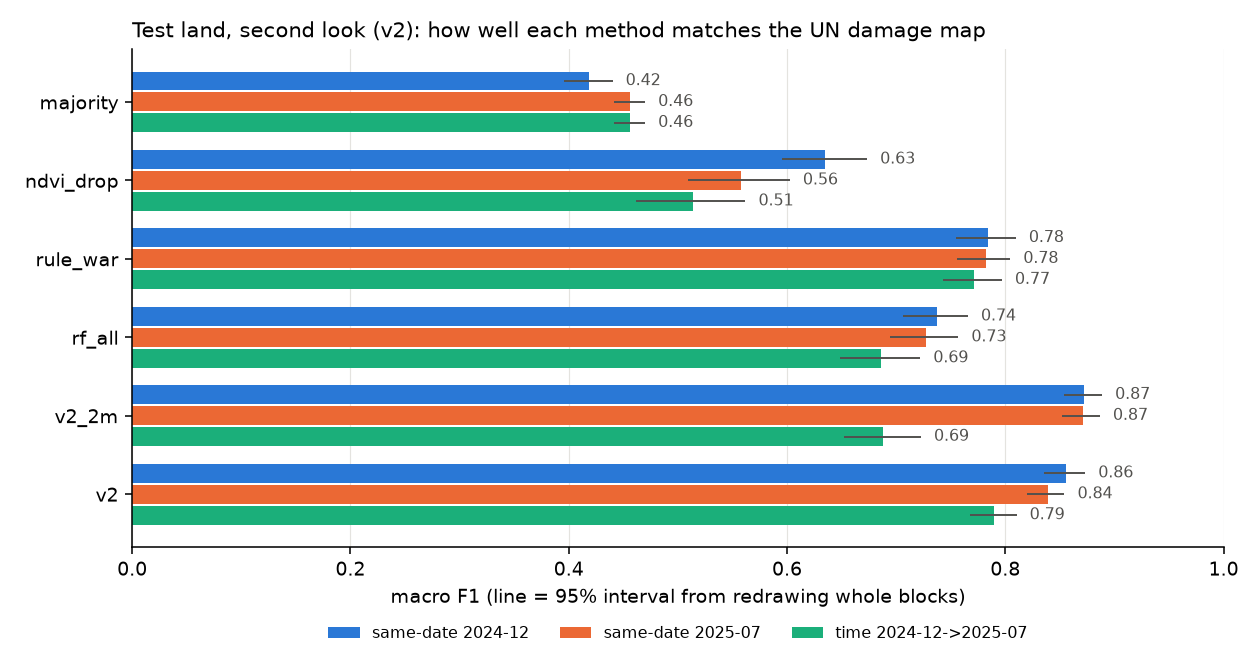

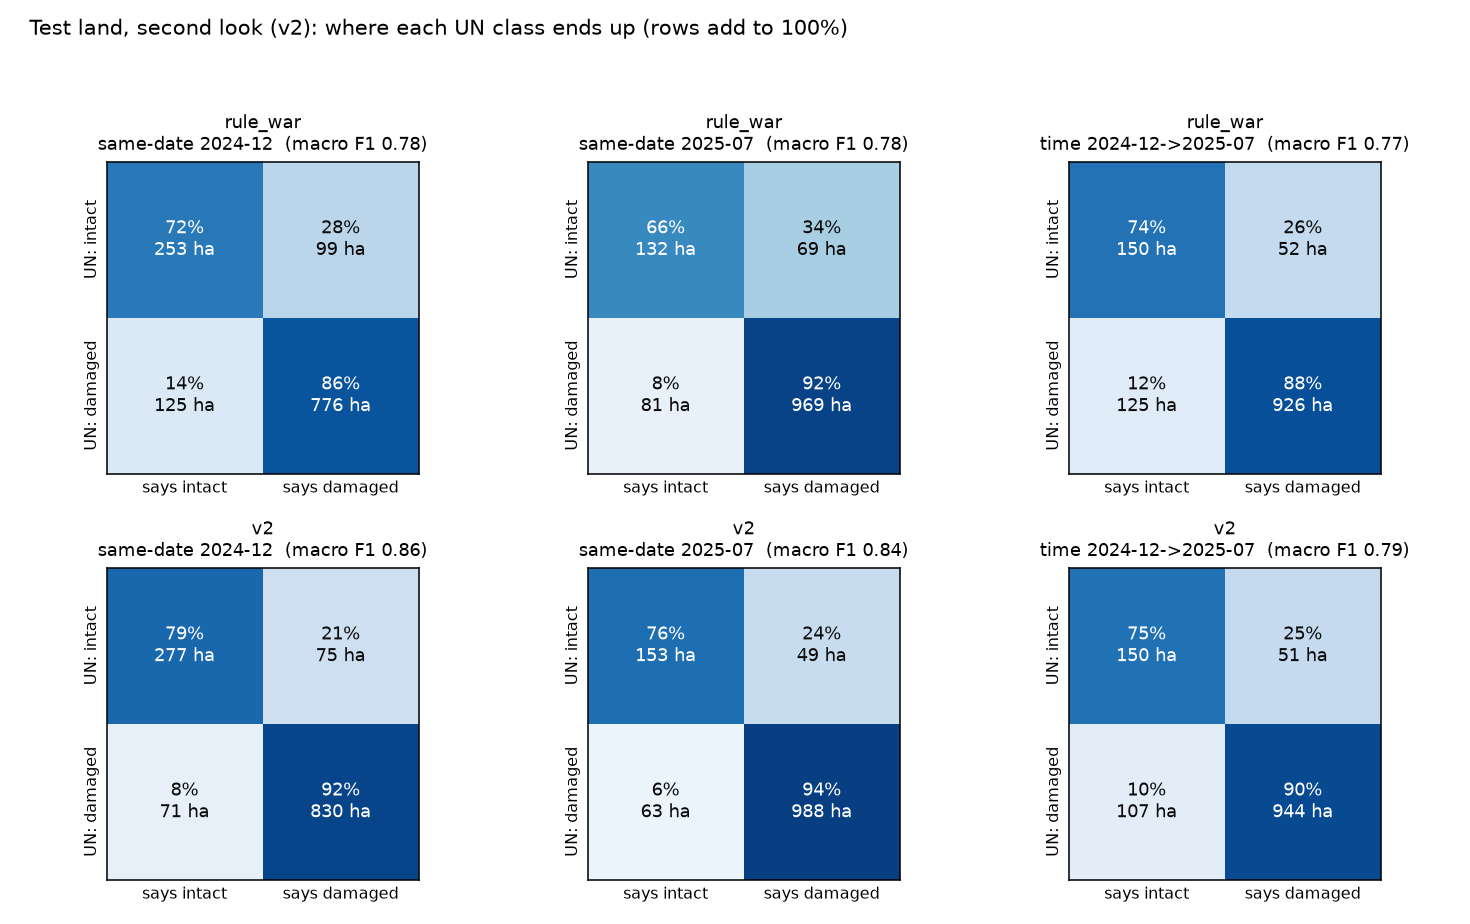

In [7]:
display(Image(str(R / "test_v2" / "scores.png"), width=800))
display(Image(str(R / "test_v2" / "confusion.png"), width=900))

## 5. A new place: Deir al-Balah
The models learned only from Khan Younis. Without any change they were scored once on **all** the cropland of the governorate to the north
(rules in `docs/test_plan_region.md`, pushed first). Recomputed here from the saved answers:

In [8]:
u = load("area_deir_al_balah/unlock.json"); print("scored once at", u["scored_at"], "| code version", u["code_version_git_commit"][:7], "|", u["n_rows"], "pixel-dates in", u["n_blocks"], "blocks")
reg = rescore("area_deir_al_balah/predictions_main.csv.gz", ["rule_war", "rf_all", "v2"])
display(reg)
both = v2[v2.method == "v2"][["exam", "macro F1"]].rename(columns={"macro F1": "v2 in Khan Younis (test land)"}).merge(
    reg[reg.method == "v2"][["exam", "macro F1"]].rename(columns={"macro F1": "v2 in Deir al-Balah (never seen)"}), on="exam")
display(both)
display(pd.read_csv(R / "area_deir_al_balah" / "by_month.csv").rename(columns={"v2_macro_f1": "v2", "rule_war_macro_f1": "simple rule"}))

scored once at 2026-11-15T01:47:44+02:00 | code version 1128679 | 518436 pixel-dates in 81 blocks


,exam,method,pixels,"UN intact, says intact","UN intact, says damaged","UN damaged, says intact","UN damaged, says damaged",accuracy,macro F1
0,Dec 2024,rule_war,259216,42509,22572,14806,179329,0.856,0.800
1,Dec 2024,rf_all,259216,40805,24276,23484,170651,0.816,0.754
2,Dec 2024,v2,259216,43052,22029,4521,189614,0.898,0.849
3,Jul 2025,rule_war,259220,26193,14664,8466,209897,0.911,0.821
4,Jul 2025,rf_all,259220,28897,11960,21527,196836,0.871,0.777
5,Jul 2025,v2,259220,30760,10097,7849,210514,0.931,0.867
6,Forward in time,rule_war,259220,29518,11339,14917,203446,0.899,0.816
7,Forward in time,rf_all,259220,22698,18159,14538,203825,0.874,0.754
8,Forward in time,v2,259220,31830,9027,14921,203442,0.908,0.836


,exam,v2 in Khan Younis (test land),v2 in Deir al-Balah (never seen)
0,Dec 2024,0.856,0.849
1,Jul 2025,0.839,0.867
2,Forward in time,0.789,0.836


,month,n,un_damaged_share,v2,simple rule
0,2023-10,258302,0.0391,0.8582,0.8625
1,2023-11,258302,0.1053,0.8370,0.8347
2,2023-12,258302,0.2507,0.8102,0.8057
3,2024-01,258302,0.3798,0.8273,0.8149
4,2024-02,258302,0.3906,0.8302,0.8181
5,2024-03,258302,0.4024,0.8250,0.8142
6,2024-04,258302,0.4324,0.8404,0.8065
7,2024-05,258302,0.4975,0.8426,0.7428
8,2024-06,259220,0.5580,0.8657,0.7829
9,2024-07,259220,0.5835,0.8790,0.7935


## 6. Where it fails
Error rates of v2 on Khan Younis test land, by kind of land. Then the four places with the most mistakes, picked by a fixed rule (not by hand).

,date,dimension,group,share_of_pixels,un_damaged_share,model_error_rate,baseline_error_rate,model_recall_damaged,model_recall_intact
0,2024-12,landcover,built-up / greenhouses,0.1616,0.7350,0.0966,0.1646,0.9517,0.7692
1,2024-12,landcover,cropland,0.5365,0.6950,0.1417,0.2101,0.8876,0.7914
2,2024-12,landcover,"other (shrub, grass, bare)",0.0810,0.4774,0.1643,0.2586,0.8617,0.8120
3,2024-12,landcover,trees (orchard),0.2210,0.8547,0.0507,0.0825,0.9806,0.7653
4,2024-12,productivity,high,0.3346,0.8695,0.0745,0.1030,0.9633,0.6736
5,2024-12,productivity,low,0.3312,0.5604,0.1571,0.2504,0.8539,0.8288
6,2024-12,productivity,medium,0.3342,0.7259,0.1173,0.1829,0.9222,0.7780
7,2024-12,edge,edge (next to the other class),0.2840,0.5500,0.2740,0.3448,0.7752,0.6658
8,2024-12,edge,interior,0.7160,0.7862,0.0535,0.1125,0.9618,0.8903
9,2024-12,greenness_now,NDVI 0.10-0.20,0.6132,0.7548,0.1168,0.1811,0.9221,0.7636


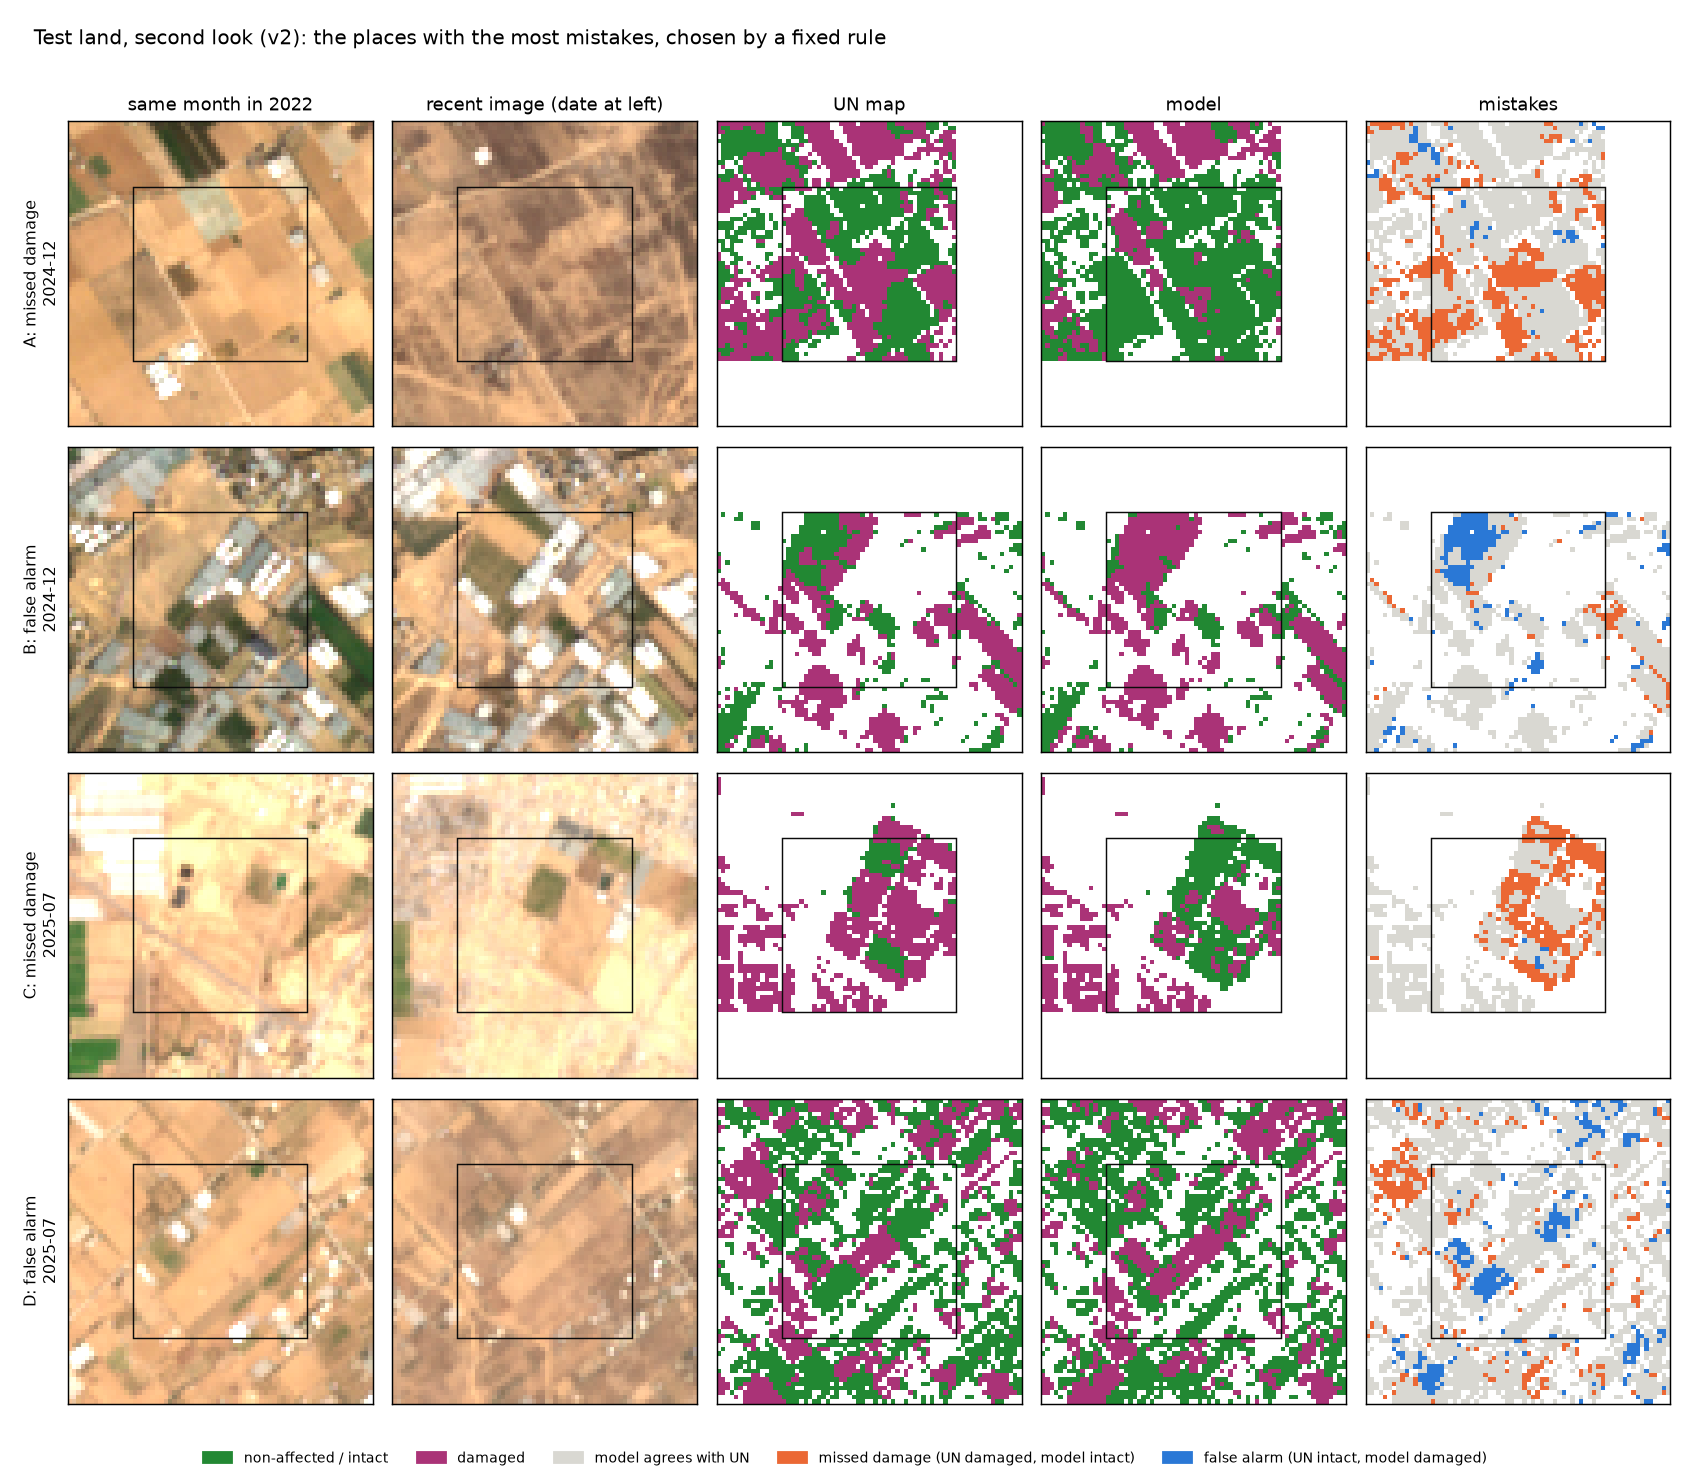

the four worst places of the FIRST model, looked at again (mistakes v1 -> v2): [(764, 131), (168, 44), (712, 184), (310, 119)]


In [9]:
sg = pd.read_csv(R / "test_v2" / "subgroups.csv")
display(sg[["date", "dimension", "group", "share_of_pixels", "un_damaged_share", "model_error_rate", "baseline_error_rate", "model_recall_damaged", "model_recall_intact"]])
display(Image(str(R / "test_v2" / "failures.png"), width=950))
print("the four worst places of the FIRST model, looked at again (mistakes v1 -> v2):", [(a["mistakes_v1"], a["mistakes_v2"]) for a in load("test_v2/v1_failures_revisited.json")])

## 7. From damage to a shortlist (the planner)
The AI estimates how much of each 1-hectare plot was damaged. A plain rule ranks the plots:
**priority = pre-war productivity x (1 - 0.6 x damaged share)**. First: does the plot-level estimate agree with the UN map on test land?
Then: in the top-ranked 10% of plots under different rankings, how much of the cropland is intact in the UN map?

In [10]:
pl = load("test_v2/plot_level.json")
display(pd.DataFrame([{"month": d, "estimate": k, "plots": e["n_plots"], "status agrees with UN": v["status_accuracy"], "average error of damaged share": v["share_mae"],
                       "bias": v["share_bias"], "rank correlation": v["spearman_r"]} for d, e in pl.items() for k, v in e["estimators"].items()]))
val = load("planner_v2/validation.json")["test"]
display(pd.DataFrame({d: {k: v[k]["un_intact_share_of_top"] for k in ("productivity only", "rule (worst month since Oct 2023)", "v1 planner", "v2 planner", "UN map (oracle)")} | {"all plots": v["all_plots_un_intact_share"]}
                      for d, v in val.items()}).rename_axis("share of the cropland in the top-ranked 10% of plots that is intact in the UN map"))

,month,estimate,plots,status agrees with UN,average error of damaged share,bias,rank correlation
0,2024-12,baseline_share,2284,0.7750,0.1203,-0.0160,0.8137
1,2024-12,model_share,2284,0.8503,0.0809,0.0090,0.8993
2,2024-12,model_calibrated,2284,0.8371,0.0850,0.0065,0.9090
3,2024-12,v1_calibrated,2284,0.7172,0.1403,-0.0143,0.7839
4,2025-07,baseline_share,2283,0.8428,0.0813,-0.0053,0.8107
5,2025-07,model_share,2283,0.8896,0.0585,-0.0074,0.8674
6,2025-07,model_calibrated,2283,0.8695,0.0690,-0.0283,0.8448
7,2025-07,v1_calibrated,2283,0.8046,0.1099,-0.0222,0.6969


,2024-12,2025-07
share of the cropland in the top-ranked 10% of plots that is intact in the UN map,,
productivity only,0.0946,0.0271
rule (worst month since Oct 2023),0.4447,0.1913
v1 planner,0.2936,0.1295
v2 planner,0.4270,0.2073
UN map (oracle),0.5179,0.2521
all plots,0.2800,0.1606


In [11]:
for month in ("2025-07", "2026-04"):
    t = pd.read_csv(R / "planner_v2" / f"plots_{month}.csv")
    print(month, "| plots by status:", t.status.value_counts().to_dict(), "| estimated damaged ha:", round(t.damaged_ha_est.sum()))
    display(t.head(5)[["rank", "lat", "lon", "cropland_ha", "status", "damaged_share", "prewar_use", "green_now", "reason", "suggested_use"]])

2025-07 | plots by status: {'mostly damaged': 5210, 'partly damaged': 2217, 'intact': 186} | estimated damaged ha: 3160


,rank,lat,lon,cropland_ha,status,damaged_share,prewar_use,green_now,reason,suggested_use
0,1,31.2887,34.3363,0.89,intact,0.2034,seasonal crops,at or above normal,"Seasonal crops, top 6% for pre-war greenness; the model estimates 20% of its 0.9 ha damaged since Oct 2023 (intact).","Ready for the next planting season: seeds, fertiliser and water. Uncertain estimate: verify on the ground first."
1,2,31.2940,34.3479,0.53,partly damaged,0.3567,seasonal crops,at or above normal,"Seasonal crops, top 12% for pre-war greenness; the model estimates 36% of its 0.5 ha damaged since Oct 2023 (partly damaged).","Plant the undamaged parts first; clear and check the rest. Damaged, but as green as normal this month: could be replanted crops, weeds o..."
2,3,31.3354,34.3590,0.69,partly damaged,0.3816,seasonal crops,below normal,"Seasonal crops, top 10% for pre-war greenness; the model estimates 38% of its 0.7 ha damaged since Oct 2023 (partly damaged).",Plant the undamaged parts first; clear and check the rest. Verify on the ground.
3,4,31.3125,34.3062,0.70,partly damaged,0.3804,orchard,below normal,"Orchard, top 10% for pre-war greenness; the model estimates 38% of its 0.7 ha damaged since Oct 2023 (partly damaged).",Survey which trees survived; repair irrigation and replant gaps. Verify on the ground.
4,5,31.3339,34.3306,0.84,partly damaged,0.4298,orchard,below normal,"Orchard, top 7% for pre-war greenness; the model estimates 43% of its 0.8 ha damaged since Oct 2023 (partly damaged).",Survey which trees survived; repair irrigation and replant gaps. Verify on the ground.


2026-04 | plots by status: {'mostly damaged': 4893, 'partly damaged': 2489, 'intact': 231} | estimated damaged ha: 3011


,rank,lat,lon,cropland_ha,status,damaged_share,prewar_use,green_now,reason,suggested_use
0,1,31.2904,34.3500,0.84,intact,0.1580,seasonal crops,at or above normal,"Seasonal crops, top 9% for pre-war greenness; the model estimates 16% of its 0.8 ha damaged since Oct 2023 (intact).","Ready for the next planting season: seeds, fertiliser and water. Uncertain estimate: verify on the ground first."
1,2,31.2887,34.3363,0.89,intact,0.2186,seasonal crops,at or above normal,"Seasonal crops, top 6% for pre-war greenness; the model estimates 22% of its 0.9 ha damaged since Oct 2023 (intact).","Ready for the next planting season: seeds, fertiliser and water. Uncertain estimate: verify on the ground first."
2,3,31.2940,34.3479,0.53,intact,0.1524,seasonal crops,at or above normal,"Seasonal crops, top 12% for pre-war greenness; the model estimates 15% of its 0.5 ha damaged since Oct 2023 (intact).","Ready for the next planting season: seeds, fertiliser and water. Uncertain estimate: verify on the ground first."
3,4,31.3107,34.3040,0.40,intact,0.1503,seasonal crops,at or above normal,"Seasonal crops, top 13% for pre-war greenness; the model estimates 15% of its 0.4 ha damaged since Oct 2023 (intact).","Ready for the next planting season: seeds, fertiliser and water. Uncertain estimate: verify on the ground first."
4,5,31.2904,34.3489,0.87,intact,0.1222,seasonal crops,at or above normal,"Seasonal crops, top 16% for pre-war greenness; the model estimates 12% of its 0.9 ha damaged since Oct 2023 (intact).","Ready for the next planting season: seeds, fertiliser and water. Verify on the ground."


## 8. Sources and tools
- **Data:** Copernicus Sentinel-2 L2A (ESA) through the Microsoft Planetary Computer; UNOSAT-FAO Gaza Strip Cropland Damage Assessment (HDX, CC BY-SA);
  ESA WorldCover 2021; OCHA COD-AB boundaries; FAO (2025), *Land availability for cultivation in the Gaza Strip as of April 2025* (CD5442EN/1/05.25).
- **Software:** Python, NumPy, pandas, GeoPandas, rasterio, odc-stac, scikit-learn, LightGBM, matplotlib.
- **AI tools:** Claude Code (Anthropic: Claude Fable 5.2, Opus 5.5, Sonnet 5.5) wrote most of the code with the author; OpenAI Codex reviewed it and recomputed the test numbers.

*This project is a prototype, not agricultural or humanitarian advice.*